In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import h5py
from sklearn.model_selection import train_test_split

# If the current accelerator is available, we will use it. Otherwise, we use the CPU.
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [2]:
def read_attr(ds, name):
    val = ds.attrs.get(name)
    if isinstance(val, bytes):
        val = val.decode('utf-8')
    if val == 'null':
        return np.nan
    return float(val)

In [3]:
h5path =  'training_gridstates.hdf5'
print("Opening:", h5path)

with h5py.File(h5path, 'r') as f:
    total_saved = int(f['total_saved_grids'][()])
    L = int(f['L'][()])

    print(f"Header: total_saved_grids={total_saved}, L={L}")

    training_grids = np.empty((total_saved, L, L), dtype=np.int8)  # smallest int type
    training_attrs = np.empty((total_saved, 4), dtype=np.float64)  # 4 float attrs per grid

    idx = 0
    for grid_name in sorted(k for k in f.keys() if k.startswith('grid_')):
        grp = f[grid_name]
        if idx >= total_saved:
            break

        training_grids[idx] = grp[()]

        ds = grp
        training_attrs[idx, 0] = read_attr(ds, 'magnetisation')
        training_attrs[idx, 1] = read_attr(ds, 'lclus_size')
        training_attrs[idx, 2] = read_attr(ds, 'committor')
        training_attrs[idx, 3] = read_attr(ds, 'committor_error')

        idx += 1

    print(f"Loaded {idx} grids. grids.shape={training_grids.shape}, attrs.shape={training_attrs.shape}")

Opening: training_gridstates.hdf5
Header: total_saved_grids=10010, L=64
Loaded 10010 grids. grids.shape=(10010, 64, 64), attrs.shape=(10010, 4)


In [48]:
from torch.utils.data import Dataset

class ising_dataset(Dataset):
    def __init__(self, data, labels, device="cpu"):
        """__init__
        Initializes Dataset object for Ising data

        Parameters:
        data: image array of Ising grids
        labels: committor values for each image
        index: index of graph within whole data set
        device: device to which pytorch tensors are loaded (default is cpu)
        train: whether data set is used for training or not (default is False)

        Returns:
        None
        """
        self.labels = labels.to(device)
        self.data = data.to(device)

    def __len__(self):
        """__len__
        Returns length of data set

        Parameters:
        None

        Returns:
        len(self.labels): length of data set
        """
        return len(self.labels)

    def __getitem__(self, idx):
        """__getitem__
        Gets individual item from data set

        Parameters:
        idx: id of item to be extracted from data set

        Returns:
        image: Ising grid image (transformed if train parameter True in __init__)
        label: committor value
        index: index of item within whole data set
        """
        data = self.data[idx]
        label = self.labels[idx]
        return data, label

In [802]:
def loss_batch(model, loss_func, xb, yb, opt=None):
    loss = loss_func(model(xb), yb)
    loss += 0.1 * ((model(torch.zeros_like(xb))).mean()) ** 2
    loss += 0.1 * ((model(torch.ones_like(xb))-1).mean()) ** 2
    
    if opt is not None:
        loss.backward()
        opt.step()
        opt.zero_grad()

    return loss.item(), len(xb)

def fit(epochs, model, loss_func, opt, train_dl, valid_dl):
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            loss_batch(model, loss_func, xb, yb, opt)  

        model.eval()
        with torch.no_grad():
            
            losses, nums = zip(
                *[loss_batch(model, loss_func, xb, yb) for xb, yb in valid_dl]
            )
        val_loss = np.sum(np.multiply(losses, nums)) / np.sum(nums)

        print(epoch, val_loss)

def get_data(train_ds, valid_ds, bs):
    return (
        DataLoader(train_ds, batch_size=bs, shuffle=True),
        DataLoader(valid_ds, batch_size=bs * 2),
    )


class cnn(torch.nn.Module):
    def __init__(self):
        super().__init__()

        channels = 10
        
        self.conv1 = torch.nn.Conv2d(1, channels, kernel_size=3, stride=1, padding=1, dilation=1, padding_mode='circular')
        self.conv2 = torch.nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=4, dilation=4, padding_mode='circular')
        self.conv3 = torch.nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=7, dilation=7, padding_mode='circular')
        #self.conv4 = torch.nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=10, dilation=10, padding_mode='circular')
        self.pool = torch.nn.AdaptiveAvgPool2d(1)
        self.fc = torch.nn.Sequential(
            #torch.nn.Linear(channels, channels),
            #torch.nn.Linear(channels, channels),
            torch.nn.Linear(channels, 1)
        )


    def forward(self, xb):
        xb = xb.view(-1, 1, 64, 64) # Batch size x channels (1)  x width x height
        #xb = self.stn(xb) 
        xb = xb + torch.nn.functional.relu(self.conv1(xb))                
        xb = xb + torch.nn.functional.relu(self.conv2(xb))  
        xb = xb + torch.nn.functional.relu(self.conv3(xb))
        #xb = xb + torch.nn.functional.relu(self.conv4(xb))
        xb = self.pool(xb)
        xb = xb.view(xb.size(0), -1)
        xb = self.fc(xb)
        return torch.sigmoid(xb) # Squeezed? to Batch size x channels (10) 

In [711]:
        self.localization = torch.nn.Sequential(
            torch.nn.Conv2d(1, 8, kernel_size=7),
            torch.nn.MaxPool2d(2, stride=2),
            torch.nn.ReLU(True),
            torch.nn.Conv2d(8, 10, kernel_size=5),
            torch.nn.MaxPool2d(2, stride=2),
            torch.nn.ReLU(True)
        )
        # Compute the correct flattened size dynamically
        with torch.no_grad():
            dummy = torch.zeros(1, 1, 64, 64)
            out = self.localization(dummy)
            self.flattened_size = out.view(1, -1).shape[1]  # should be 10 * 12 * 12 = 1440

        # Regressor for the 3x2 affine matrix
        self.fc_loc = torch.nn.Sequential(
            torch.nn.Linear(self.flattened_size, 32),
            torch.nn.ReLU(True),
            torch.nn.Linear(32, 3 * 2)
        )

        # Initialize the weights/bias with identity transform
        self.fc_loc[2].weight.data.zero_()
        self.fc_loc[2].bias.data.copy_(torch.tensor([1, 0, 0, 0, 1, 0], dtype=torch.float))

    def stn(self, x):
        xs = self.localization(x)
        xs = xs.view(-1, self.flattened_size)
        theta = self.fc_loc(xs)
        theta = theta.view(-1, 2, 3)

        grid = torch.nn.functional.affine_grid(theta, x.size(), align_corners=False)
        x = torch.nn.functional.grid_sample(x, grid, align_corners=False)
        return x

IndentationError: unexpected indent (1501913048.py, line 1)

In [803]:
data = torch.tensor(training_grids, dtype=torch.float32)
labels = torch.tensor(training_attrs[:,2], dtype=torch.float32)
labels = labels.unsqueeze(1)
data = (data+1)/2

num_bins = 10
samples_per_bin = 50  # how many to sample from each bin

# Define bins
bins = np.linspace(0, 1, num_bins + 1)
num_to_sample = len(data)

subset_indices = []

for i in range(num_bins):
    # Find indices of labels in this bin
    bin_idx = np.where((labels >= bins[i]) & (labels < bins[i+1]))[0]

    # If bin is too small, skip or take all
    if len(bin_idx) == 0:
        continue

    # Sample from this bin (with or without replacement)
    num_to_sample = min(num_to_sample, len(bin_idx))
    
for i in range(num_bins):
    # Find indices of labels in this bin
    bin_idx = np.where((labels >= bins[i]) & (labels < bins[i+1]))[0]
    
    selected = np.random.choice(bin_idx, size=num_to_sample, replace=False)
    
    subset_indices.extend(selected)

# Convert to NumPy array
subset_indices = np.array(subset_indices)

# Get the corresponding labels
data = data[subset_indices]
labels = labels[subset_indices]

x_train, x_valid, y_train, y_valid = train_test_split(data, labels, test_size=0.2)

trainset = ising_dataset(x_train, y_train, device=device)
valset = ising_dataset(x_valid, y_valid, device=device)

In [804]:
from torch.utils.data import DataLoader

train_loader = DataLoader(trainset, shuffle=True, batch_size=20)
val_loader = DataLoader(valset, shuffle=False)

In [805]:
# Define model to train
model1 = cnn()
model1.to(device)

# Select optimiser and learning rate
loss_func =  torch.nn.functional.mse_loss
lr = 0.001
opt = torch.optim.Adam(model1.parameters(), lr=lr)

# Fit the model
epochs = 20
fit(epochs, model1, loss_func, opt, train_loader, val_loader)

0 0.09860831109464777
1 0.08700843468042356
2 0.07252814242502256
3 0.05212434432326759
4 0.03145247821848155
5 0.020042041087955504
6 0.015954676630511186
7 0.011849581670522101
8 0.0098692321033533
9 0.00937694750164341
10 0.008225689938144012
11 0.006634239137142407
12 0.006742873578777831
13 0.005902638408751583
14 0.005779955816177214
15 0.005191212683341143
16 0.005422765049936098
17 0.00497391006182606
18 0.005481073824981019
19 0.0045948995445672025


Output logits   :  0.0824054554104805 Label :  0.0546875


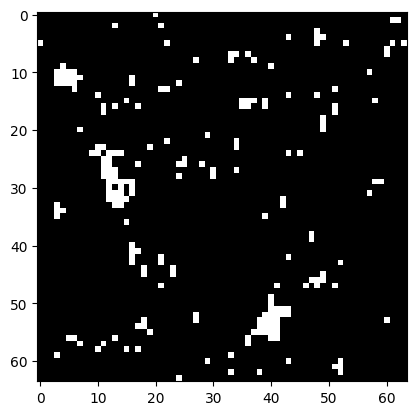

Output logits   :  0.0824054554104805 Label :  0.0546875


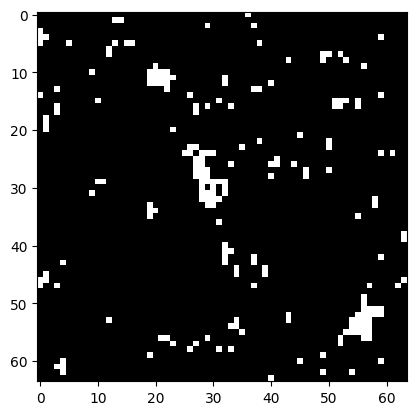

Norm of output difference due to shift : 0.0
Accuracy for validation set :  56.12244897959184  %
Number of parameters        :  1931


In [806]:
model1.eval()
with torch.no_grad():

    iimg = np.random.randint(len(x_valid))
    plt.imshow(x_valid[iimg].reshape((64, 64)), cmap="gray")
    out = model1(x_valid[iimg].to(device)).squeeze()
    print("Output logits   : ",out.item(), "Label : ", y_valid[iimg].item())
    plt.show()

    # roll the image
    nroll = 16
    shifted_img = x_valid[iimg].reshape((64, 64))
    shifted_img = torch.roll(shifted_img, (0, nroll), dims=(0, 1))
    shifted_img = shifted_img.reshape(64*64)

    plt.imshow(shifted_img.reshape((64, 64)), cmap="gray")
    out_shifted = model1(shifted_img.to(device)).squeeze()
    print("Output logits   : ",out_shifted.item(), "Label : ", y_valid[iimg].item())
    plt.show()

    # Print difference
    print("Norm of output difference due to shift :", np.linalg.norm((out_shifted - out).cpu().detach().numpy()))

    # Add a check of accuracy on the validation set (should probably do this in batches)
    prediction = np.zeros(len(y_valid))
    cc = 0
    for iimg, image in enumerate(x_valid):
        pred = model1(image.to(device)).item()
        prediction[iimg] = pred
        if abs(pred - y_valid[iimg].item()) < 0.05:
            cc += 1

    print("============================================")
    print("Accuracy for validation set : ",100*cc/len(x_valid)," %")
    print("Number of parameters        : ",sum(p.numel() for p in model1.parameters() if p.requires_grad))
    print("============================================")    


0.04990752786397934
RMSE:  0.009098057121950753


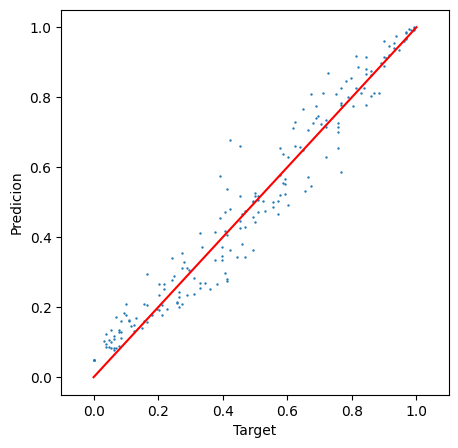

In [807]:
all_minus = torch.full((64, 64), 0.0).to(device)
print(model1(all_minus).item())
print("RMSE: ", np.sqrt(np.mean(y_valid.numpy()-prediction)**2))
plt.figure(figsize=(5, 5))
plt.scatter(y_valid, prediction, s=0.5)
plt.plot([0,1],[0,1], c="red")
plt.xlim(-0.1, 1.1)
plt.xlabel("Target")
plt.ylabel("Predicion")
plt.show()

In [445]:
import numpy as np
from sklearn.metrics import mean_squared_error

def get_worst_val_bin(labels_val, preds_val, num_bins=10):
    bins = np.linspace(0, 1, num_bins + 1)
    rmse_per_bin = []
    bin_ranges = []

    for i in range(num_bins):
        idx = np.where((labels_val >= bins[i]) & (labels_val < bins[i + 1]))[0]
        if len(idx) == 0:
            rmse = 0
        else:
            rmse = np.sqrt(np.sum((labels_val[idx] - preds_val[idx]) ** 2))
        rmse_per_bin.append(rmse)
        bin_ranges.append((bins[i], bins[i + 1]))

    worst_bin_idx = np.argmax(rmse_per_bin)
    worst_range = bin_ranges[worst_bin_idx]
    return worst_range

def get_training_subset_in_range(labels_train, lower, upper, sample=10):
    idx = np.where((labels_train >= lower) & (labels_train < upper))[0]
    idx = np.random.choice(idx, sample, replace=False)
    return idx

In [409]:
lower, upper = get_worst_val_bin(y_valid.numpy(), prediction, num_bins=10)
index = get_training_subset_in_range(y_train, lower, upper)

0 0.020902107104992827
1 0.038159146691358545
2 0.053887829059814846
3 0.06597010992110117
4 0.07390677925740936
Accuracy for validation set :  35.74660633484163  %
Number of parameters        :  2841


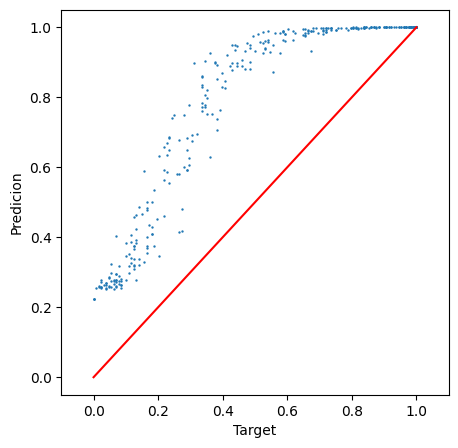

In [436]:
epochs = 5
trainset = ising_dataset(x_train[index], y_train[index], device=device)
valset = ising_dataset(x_valid, y_valid, device=device)
train_loader = DataLoader(trainset, shuffle=True, batch_size=20)
val_loader = DataLoader(valset, shuffle=False)

fit(epochs, model1, loss_func, opt, train_loader, test_loader)
    
cc = 0
for iimg, image in enumerate(x_valid):
    pred = model1(image.to(device)).item()
    prediction[iimg] = pred
    if abs(pred - y_valid[iimg].item()) < 0.05:
        cc += 1

print("============================================")
print("Accuracy for validation set : ",100*cc/len(x_valid)," %")
print("Number of parameters        : ",sum(p.numel() for p in model1.parameters() if p.requires_grad))
print("============================================")  

lower, upper = get_worst_val_bin(y_valid.numpy(), prediction, num_bins=10)
index = get_training_subset_in_range(y_train, lower, upper)

plt.figure(figsize=(5, 5))
plt.scatter(y_valid, prediction, s=0.5)
plt.plot([0,1],[0,1], c="red")
plt.xlim(-0.1, 1.1)
plt.xlabel("Target")
plt.ylabel("Predicion")
plt.show()